# HW5: Dyna-Q — Integrating Planning, Acting, and Learning

> - Full Name: **Yasamin Rajabi**
> - Student ID: **402111197**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/DeepRLCourse/Homework-5-Questions/blob/main/RL_HW5_Dyna.ipynb)
[![Open In kaggle](https://kaggle.com/static/images/open-in-kaggle.svg)](https://kaggle.com/kernels/welcome?src=https://raw.githubusercontent.com/DeepRLCourse/Homework-5-Questions/main/RL_HW5_Dyna.ipynb)

## Overview

Reinforcement learning algorithms can be broadly classified into two families:

- **Model-free methods** (e.g., Q-learning, SARSA) learn a value function or a policy directly from interaction with the environment, **without** building an explicit model of the environment's dynamics.
- **Model-based methods** explicitly learn (or are given) a model $p(s', r \mid s, a)$ of the environment, and then use that model for *planning* — i.e., computing improved values or policies via simulated experience.

**Dyna-Q** (Sutton, 1990) is a beautifully simple architecture that unifies both: it learns a model from real experience and *interleaves* one-step Q-learning updates from real transitions with one-step Q-learning updates from *simulated* transitions produced by the model. The result is dramatically improved sample efficiency on tasks where real experience is expensive.

In this assignment you will:

1. Familiarize yourself with the [**Cliff Walking**](https://gymnasium.farama.org/environments/toy_text/cliff_walking/) environment.
2. Implement $\varepsilon$-greedy and greedy policies.
3. Implement **Dyna-Q** for a deterministic environment.
4. Investigate how the number of planning steps affects learning.
5. Improve learning with **reward shaping**.
6. Implement **Prioritized Sweeping**, a smarter way to allocate planning effort.
7. (Bonus) Extend everything to the larger, stochastic **Taxi-v3** environment.

Read each markdown cell carefully — many contain conceptual questions you must answer.

In [14]:
# @title Imports

import random
import numpy as np
import gymnasium as gym
from tqdm import trange
from heapq import heappush, heappop
from collections import defaultdict

import matplotlib
from matplotlib import pyplot as plt
import matplotlib.patches as patches
from matplotlib.gridspec import GridSpec

import base64
import imageio
import IPython

import seaborn as sns

In [2]:
# @title Visualization Functions

def embed_mp4(filename):
    video = open(filename, 'rb').read()
    b64 = base64.b64encode(video)
    tag = '''
    <video width="640" height="480" controls>
    <source src="data:video/mp4;base64,{0}" type="video/mp4">
    Your browser does not support the video tag.
    </video>'''.format(b64.decode())
    return IPython.display.HTML(tag)


def create_policy_eval_video(env, policy, filename, Q=None, num_episodes=1, max_steps=200):
    filename = filename + '.mp4'
    with imageio.get_writer(filename, fps=env.metadata.get('render_fps', 4)) as video:
        for _ in range(num_episodes):
            state, info = env.reset()
            video.append_data(env.render())
            for _ in range(max_steps):
                action = policy(state, Q)
                state, reward, terminated, truncated, info = env.step(action)
                video.append_data(env.render())
                if terminated or truncated:
                    break
    return embed_mp4(filename)


def plot_rewards(rewards, average_range=None, ax=None, show=False):
    if ax is None:
        fig, ax = plt.subplots()
    xs = range(1, len(rewards) + 1)
    ax.plot(xs, rewards, marker='.', linestyle='--', alpha=0.4, label='Episode Reward')
    ax.plot(xs, np.cumsum(rewards) / xs, label='Cumulative Average')
    if len(rewards) >= 20:
        window = min(50, len(rewards) // 5)
        smooth = np.convolve(rewards, np.ones(window)/window, mode='valid')
        ax.plot(range(window, len(rewards) + 1), smooth, label=f'Rolling Mean (w={window})')
    ax.legend()
    ax.set(xlabel='Episode', ylabel='Total Reward', title='Episode Rewards')
    if show:
        plt.show()


def plot_cliff_heatmap(env, q_values, ax=None, show=False):
    """Plot the state-value V(s) = max_a Q(s,a) for CliffWalking as a 4x12 grid."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 3))
    rows, cols = 4, 12
    v = q_values.max(axis=1).reshape(rows, cols)
    best_a = q_values.argmax(axis=1)
    act_arrows = {0: '↑', 1: '→', 2: '↓', 3: '←'}
    labels = np.array([act_arrows[a] for a in best_a]).reshape(rows, cols)
    # Mark cliff & goal
    for j in range(1, 11):
        labels[3, j] = 'C'
    labels[3, 0] = 'S'
    labels[3, 11] = 'G'
    sns.heatmap(v, cmap='RdYlGn', annot=labels, fmt='s', ax=ax, cbar_kws={'label': 'V(s)'})
    ax.set_title('Greedy Policy & State Values')
    if show:
        plt.show()


def plot_performance(env, q_values, reward_sums):
    fig = plt.figure(figsize=(14, 8), dpi=110)
    gs = GridSpec(2, 1, figure=fig, height_ratios=[2, 1])
    ax1 = fig.add_subplot(gs[0, 0])
    plot_rewards(reward_sums, ax=ax1)
    ax2 = fig.add_subplot(gs[1, 0])
    plot_cliff_heatmap(env, q_values, ax=ax2)
    plt.tight_layout()
    plt.show()

# 1. Explore the Environment (5 points)

## The Cliff Walking Problem

**Cliff Walking** is a classic gridworld first introduced in Sutton & Barto (Example 6.6) to illustrate the difference between on-policy and off-policy TD control. The world is a $4 \times 12$ grid:

- The agent starts at the bottom-left corner **S**.
- The goal **G** is at the bottom-right corner.
- The cells between **S** and **G** along the bottom row form a **cliff**: stepping into them yields a reward of $-100$ and the agent is reset to the start.
- Every other transition yields a reward of $-1$.
- Actions: `0=Up, 1=Right, 2=Down, 3=Left`.
- The environment is **deterministic**.

Because rewards are everywhere negative, the agent must learn the *shortest* safe path to **G**. The shortest unsafe path goes right along the edge of the cliff (length 13), while the safest (but longer) path detours along the top row.

**Question 1.1.** Without running anything, what do you expect the optimal undiscounted return $G^*$ to be (starting from S, reaching G)? Show your reasoning.

`Your Answer:`
-13, Because when we don't step into the cliff (which is obviously not optimal), all rewards are negative and same in each step. So the maximum total reward is when we find the shortest path to the goal, which is the path of length 13 that has a negative reward -1 at each step.

In [5]:
env = gym.make('CliffWalking-v1', render_mode='rgb_array')

# TODO: Print the observation space and the action space
print('Observation space:', env.observation_space)
print('Action space:', env.action_space)
print('Number of states:', env.observation_space.n)
print('Number of actions:', env.action_space.n)

Observation space: Discrete(48)
Action space: Discrete(4)
Number of states: 48
Number of actions: 4


Define a uniform random policy.

In [6]:
def random_policy(*args):
    # TODO: Select a uniformly random action
    action = env.action_space.sample()
    return action

Visualize the random policy. (Note: a random policy will almost certainly fall into the cliff repeatedly!)

In [7]:
create_policy_eval_video(env, random_policy, 'random_policy', num_episodes=2, max_steps=50)

c:\Users\User\AppData\Local\Programs\Python\Python313\Lib\site-packages\pygame\pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


# 2. Policies (5 points)

## Exploration vs. Exploitation

Any control algorithm must balance two competing pressures:

- **Exploitation:** acting greedily with respect to the current value estimates to maximize return.
- **Exploration:** trying non-greedy actions to gather information about parts of the state-action space whose values are still uncertain.

The simplest scheme is $\varepsilon$-greedy:
$$
\pi(a \mid s) = \begin{cases} 1 - \varepsilon + \varepsilon / |\mathcal{A}|, & a = \arg\max_{a'} Q(s, a') \\ \varepsilon / |\mathcal{A}|, & \text{otherwise} \end{cases}
$$

**Question 2.1.** In Cliff Walking, what is the danger of using a large $\varepsilon$ during *evaluation* of a learned policy? What is the danger of using too small an $\varepsilon$ during *learning*?

`Your Answer:`
When evaluating a policy, using a very large epsilon can cause the agent to execute random actions in the environment instead of following the learned policy, resulting in a poor evaluation of that policy — in other words, weak exploitation. During learning, when epsilon is too small, the agent performs insufficient exploration and may fail to discover the optimal actions effectively.

In [8]:
def greedy_policy(state: int, q_values: np.ndarray) -> int:
    # TODO: Return argmax_a Q(state, a)
    action = np.argmax(q_values[state])
    return action

In [9]:
def epsilon_greedy_policy(state: int, q_values: np.ndarray, epsilon: float) -> int:
    # TODO: With probability epsilon, take a random action;
    # otherwise act greedily according to Q
    if np.random.random() < epsilon:
        action = env.action_space.sample() 
    else:
        action = np.argmax(q_values[state])
    return action

# 3. Dyna-Q (25 points)

## The Dyna Architecture

Dyna-Q maintains three things in parallel:

1. **A value function** $Q(s,a)$, updated by tabular one-step Q-learning.
2. **A model** of the environment. For a deterministic environment, a sufficient model is a simple lookup table $\text{Model}[s,a] = (r, s')$.
3. **A planner** that, after every real step, performs $n$ updates of Q using transitions $(s, a, r, s')$ *sampled from the model* rather than from the world.

The full update rules are:

**Direct RL (from real experience):**
$$
Q(s_t, a_t) \leftarrow Q(s_t, a_t) + \alpha\Big[r_t + \gamma \max_{a'} Q(s_{t+1}, a') - Q(s_t, a_t)\Big]
$$

**Model learning (deterministic):**
$$
\text{Model}[s_t, a_t] \leftarrow (r_t, s_{t+1})
$$

**Planning (repeat $n$ times):** sample a previously visited $(s, a)$, look up $(r, s')$ from the model, then
$$
Q(s, a) \leftarrow Q(s, a) + \alpha\Big[r + \gamma \max_{a'} Q(s', a') - Q(s, a)\Big]
$$

**Question 3.1.** Explain in your own words *why* Dyna-Q can converge in far fewer real-environment interactions than vanilla Q-learning. What is the computational cost?

`Your Answers:`
Dyna-Q extracts n+1 Q-updates from each real interaction — one from the real transition and n from simulated ones using the learned model. This reuse of experience drastically reduces the number of real interactions needed. The trade-off is an O(n) computational overhead per real step.

**Question 3.2.** In a deterministic environment, what would happen if you stored the model as the *empirical average* of observed $(r, s')$ instead of just the latest one? Would it matter here?

`Your Answers:`
In a deterministic environment, the same (s,a)(s, a)
(s,a) always produces the same (r,s′)(r, s')
(r,s′), so the empirical average equals the latest observation — there is no difference. This distinction only matters in stochastic environments.

## 3.1 Planning (10 points)

Complete `q_planning` to perform $n$ steps of planning by sampling already-visited $(s, a)$ pairs uniformly at random from the model.

In [11]:
def q_planning(model: dict, q: np.ndarray, alpha: float, gamma: float, n: int) -> np.ndarray:
    """Perform n planning updates from a deterministic model.

    model : dict[state] -> dict[action] -> (reward, next_state)
    """
    # TODO: If the model is empty, return q unchanged.
    if not model:
        return q

    # TODO: Perform n planning iterations:
    for _ in range(n):
        #   1. Sample a state s uniformly from model.keys().
        s = random.choice(list(model.keys()))
        #   2. Sample an action a uniformly from model[s].keys().
        a = random.choice(list(model[s].keys()))
        #   3. Retrieve (r, s') from model[s][a].
        r, s_next = model[s][a]
        #   4. Apply the Q-learning update.
        q[s, a] += alpha * (r + gamma * np.max(q[s_next]) - q[s, a])

    return q

## 3.2 Learning (15 points)

Now put everything together. At each real step you must:

1. Select an action with $\varepsilon$-greedy.
2. Step the real environment.
3. Perform the direct Q-learning update.
4. Update the model.
5. Perform $n$ planning steps.

Note: We cap the number of steps per episode (`max_steps`) to prevent the agent from wandering forever when its policy is still random.

In [10]:
def dyna_q(n_episodes: int, env: gym.Env, epsilon: float, alpha: float,
           gamma: float, n: int, max_steps: int = 200) -> tuple[np.ndarray, np.ndarray]:
    """Dyna-Q for a deterministic environment."""

    reward_sums = np.zeros(n_episodes)
    q = np.zeros((env.observation_space.n, env.action_space.n))
    model = defaultdict(dict)

    for episode_i in (pbar := trange(n_episodes, leave=False)):
        state, info = env.reset()
        reward_sum, terminal, steps = 0.0, False, 0

        while not terminal and steps < max_steps:
            # TODO: 1. Select an action via epsilon-greedy.
            action = epsilon_greedy_policy(state, q, epsilon)

            # TODO: 2. Step the environment.
            next_state, reward, terminated, truncated, info = env.step(action)
            terminal = terminated or truncated

            # TODO: 3. Direct Q-learning update.
            q[state, action] += alpha * (reward + gamma * np.max(q[next_state]) - q[state, action])

            # TODO: 4. Update the deterministic model.
            model[state][action] = (reward, next_state)

            # TODO: 5. Planning step(s).
            q = q_planning(model, q, alpha, gamma, n)

            # TODO: 6. Bookkeeping: state <- next_state; accumulate reward; increment steps.
            state = next_state
            reward_sum += reward
            steps += 1

        pbar.set_description(f'Episode {episode_i}, R={reward_sum:.0f}')
        reward_sums[episode_i] = reward_sum

    return q, reward_sums

# 4. Experiments (15 points)

Run Dyna-Q with several values of the planning parameter $n$ (e.g. $n \in \{0, 5, 50\}$).
Note that **$n = 0$ recovers pure Q-learning**.

After running, answer the following:

**Question 4.1.** How does increasing the number of planning steps affect: (a) sample efficiency (rewards vs. episodes), and (b) wall-clock time per episode?

`Your Answers:`

Sample efficiency: Increasing n dramatically improves sample efficiency — the agent reaches near-optimal returns in far fewer episodes, because each real step generates n additional planning updates that propagate value information faster across the state space.

Wall-clock time: Each planning step adds computational overhead, so higher n increases wall-clock time per episode by approximately O(n).

**Question 4.2.** Suppose the *first* successful trajectory occurs at episode $N_1$. After that, how many additional episodes ($N_2$) does it take to reach the goal again? Explain how $n$ affects each of $N_1$ and $N_2$, and *why* the effects differ.

`Your Answers:`

The effect of $n$ on $N_1$ is relatively **limited**. Before reaching the goal for the first time, the model contains no information about goal-adjacent transitions, so planning cannot propagate values backward from the goal. Higher $n$ only helps by reinforcing already-visited transitions more thoroughly, slightly guiding exploration toward unvisited regions.

After the first success, the model now contains the transitions leading to the goal. Here, higher $n$ has a much **stronger** effect — planning rapidly reinforces the successful path by repeatedly updating Q-values along it, so the agent rediscovers and consistently follows the goal path in very few additional episodes. This is why the effects differ: $N_1$ is a *discovery* problem where planning has little to work with, while $N_2$ is a *reinforcement* problem where planning can fully exploit the learned model.


**Question 4.3.** What happens to the *learned path* (cliff-edge vs. safer detour) as you vary $\varepsilon$? Why? Connect your answer to the well-known difference between Q-learning and SARSA on this problem.

`Your Answers:`

With small $\varepsilon$, the greedy policy converges to the **cliff-edge path** (optimal undiscounted return $-13$), similar to Q-learning. With large $\varepsilon$, random actions near the cliff cause frequent $-100$ penalties, pushing Q-values of cliff-adjacent states down and forcing the agent toward the **safer upper detour**, similar to SARSA. This is exactly the Q-learning vs. SARSA distinction: Q-learning learns the optimal policy regardless of exploration noise, while SARSA learns a safer policy that accounts for its own exploratory behavior.

**Question 4.4.** Cliff Walking is fully deterministic. Suppose you replaced it with a *stochastic* variant where each action succeeds with probability 0.8 and otherwise slips perpendicular. What failure modes would the current **deterministic** Dyna-Q exhibit? Propose how you would modify the model to fix this.

`Your Answers:`

**Failure modes:** The deterministic model stores only the last observed $(r, s')$ for each $(s, a)$. In a stochastic environment, this single sample is an unreliable estimate of the true transition distribution — planning would use a biased model and produce incorrect Q-values.

**Fix:** Replace the single stored transition with an empirical distribution: accumulate counts $C(s'|s,a)$ and average rewards $\bar{r}(s,a)$, then during planning sample $s' \sim \hat{p}(\cdot|s,a)$ and use $\bar{r}(s,a)$.

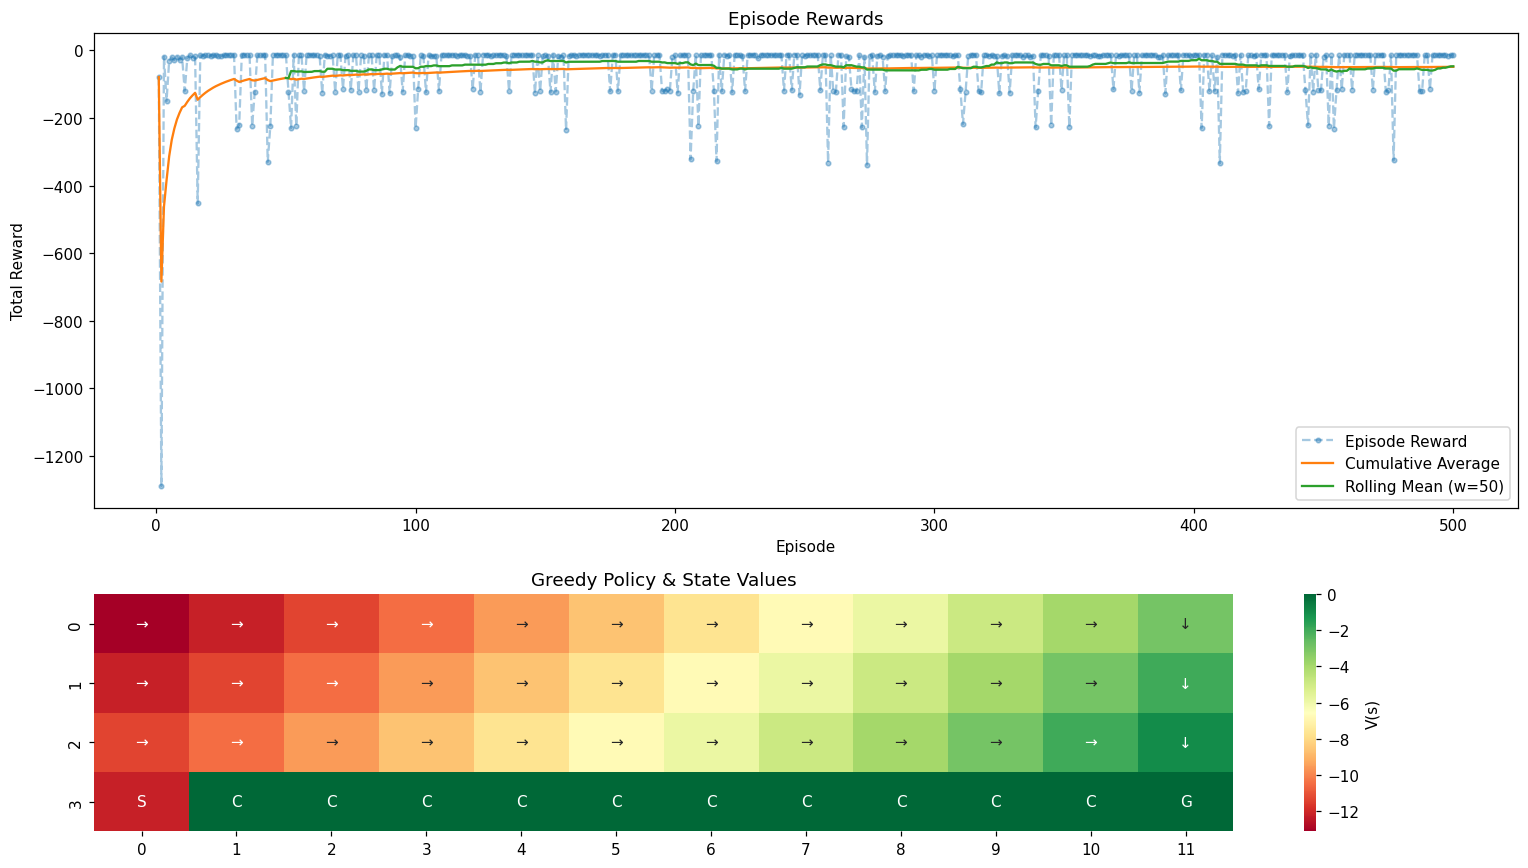

In [15]:
np.random.seed(2025)
random.seed(2025)

params = {
    'epsilon': 0.1,    # epsilon-greedy exploration rate
    'alpha':   0.5,    # learning rate (tabular, deterministic env => can be large)
    'gamma':   0.99,   # discount factor
    'n':       10,     # number of planning steps per real step
}

n_episodes = 500

env = gym.make('CliffWalking-v1')

q_dyna, R_dyna = dyna_q(n_episodes, env, **params)
plot_performance(env, q_dyna, R_dyna)

**Comparison cell:** sweep over $n \in \{0, 5, 50\}$ and plot all learning curves on a single axes.

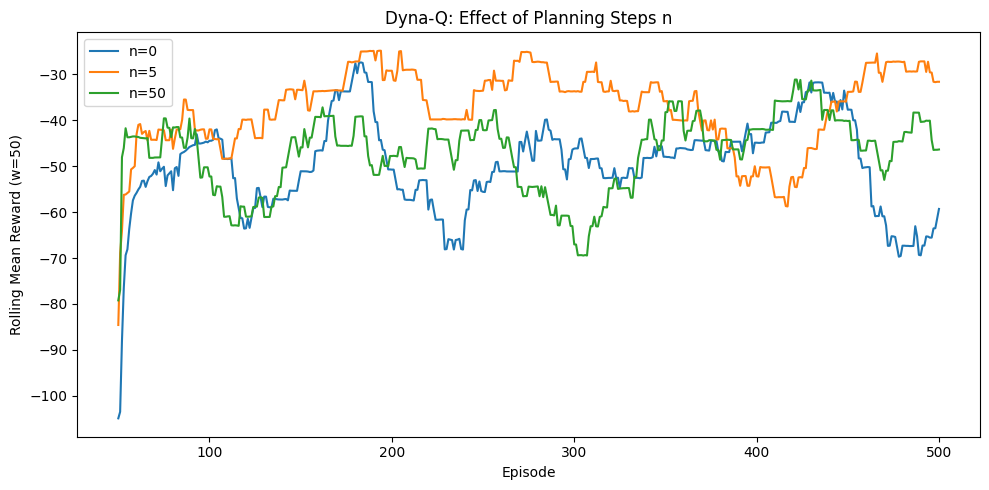

In [16]:
# TODO: For each n in [0, 5, 50], run dyna_q and plot the rolling-mean reward curve.
# Use the same seed and the same other hyperparameters as above.

ns = [0, 5, 50]
results = {}

for n in ns:
    np.random.seed(2025)
    random.seed(2025)
    env = gym.make('CliffWalking-v1')
    _, R = dyna_q(n_episodes, env, epsilon=0.1, alpha=0.5, gamma=0.99, n=n)
    results[n] = R

fig, ax = plt.subplots(figsize=(10, 5))
for n, R in results.items():
    window = 50
    smooth = np.convolve(R, np.ones(window)/window, mode='valid')
    ax.plot(range(window, n_episodes + 1), smooth, label=f'n={n}')

ax.set(xlabel='Episode', ylabel='Rolling Mean Reward (w=50)',
       title='Dyna-Q: Effect of Planning Steps n')
ax.legend()
plt.tight_layout()
plt.show()

# 5. Improving Performance (15 points)

Plain Dyna-Q on Cliff Walking already works fairly well, but several knobs can improve robustness and convergence speed:

1. **Optimistic initialization.** Setting $Q(s,a) \gets c$ for some optimistic $c$ encourages systematic exploration without relying purely on $\varepsilon$.
2. **Decaying $\varepsilon$.** Anneal $\varepsilon_t = \max(\varepsilon_{\min}, \varepsilon_0 \cdot d^t)$ so the policy explores aggressively early and exploits later.
3. **Decaying $\alpha$.** Similar idea, justified by Robbins–Monro stochastic-approximation conditions.
4. **Boltzmann (softmax) exploration** instead of $\varepsilon$-greedy.
5. **Adaptive planning budget.** Increase $n$ only after the agent has accumulated enough model entries.

Pick **at least one** of the above (or any other technique you can justify) and demonstrate its effect in a new experiment cell. **Do not overwrite your previous experiments** — leave them for comparison.

**Question 5.1.** Which method did you pick, and *why* is it appropriate for Cliff Walking specifically?

`Your Answer:`
We chose **decaying $\varepsilon$** because Cliff Walking has a particularly harsh penalty of $-100$ for exploratory mistakes near the cliff. A fixed $\varepsilon$ forces the agent to keep taking random actions even after learning a good policy, causing repeated catastrophic falls that destabilize the learned Q-values.

As clearly visible in the plot, decaying $\varepsilon$ starts lower in early episodes (due to higher initial exploration causing more cliff falls), but steadily improves and **surpasses fixed $\varepsilon$** around episode 200, ultimately converging to a significantly higher rolling mean reward near $-13$. The fixed $\varepsilon=0.1$ agent plateaus around $-50$ and never fully converges, since it keeps falling off the cliff due to persistent random actions. This confirms that decaying $\varepsilon$ is particularly appropriate for Cliff Walking: aggressive early exploration builds a good model quickly, while the gradual shift to exploitation eliminates unnecessary cliff falls in later episodes. As we see results are more robust with less variance.

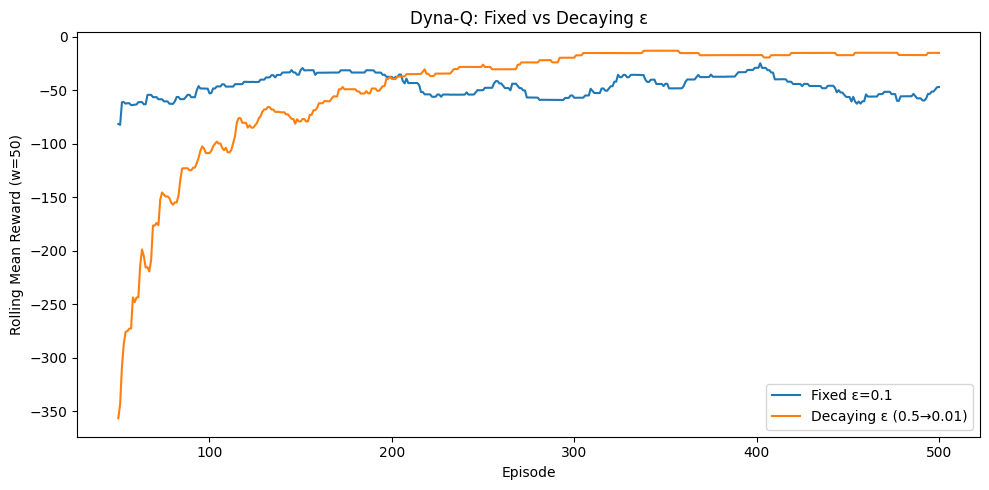

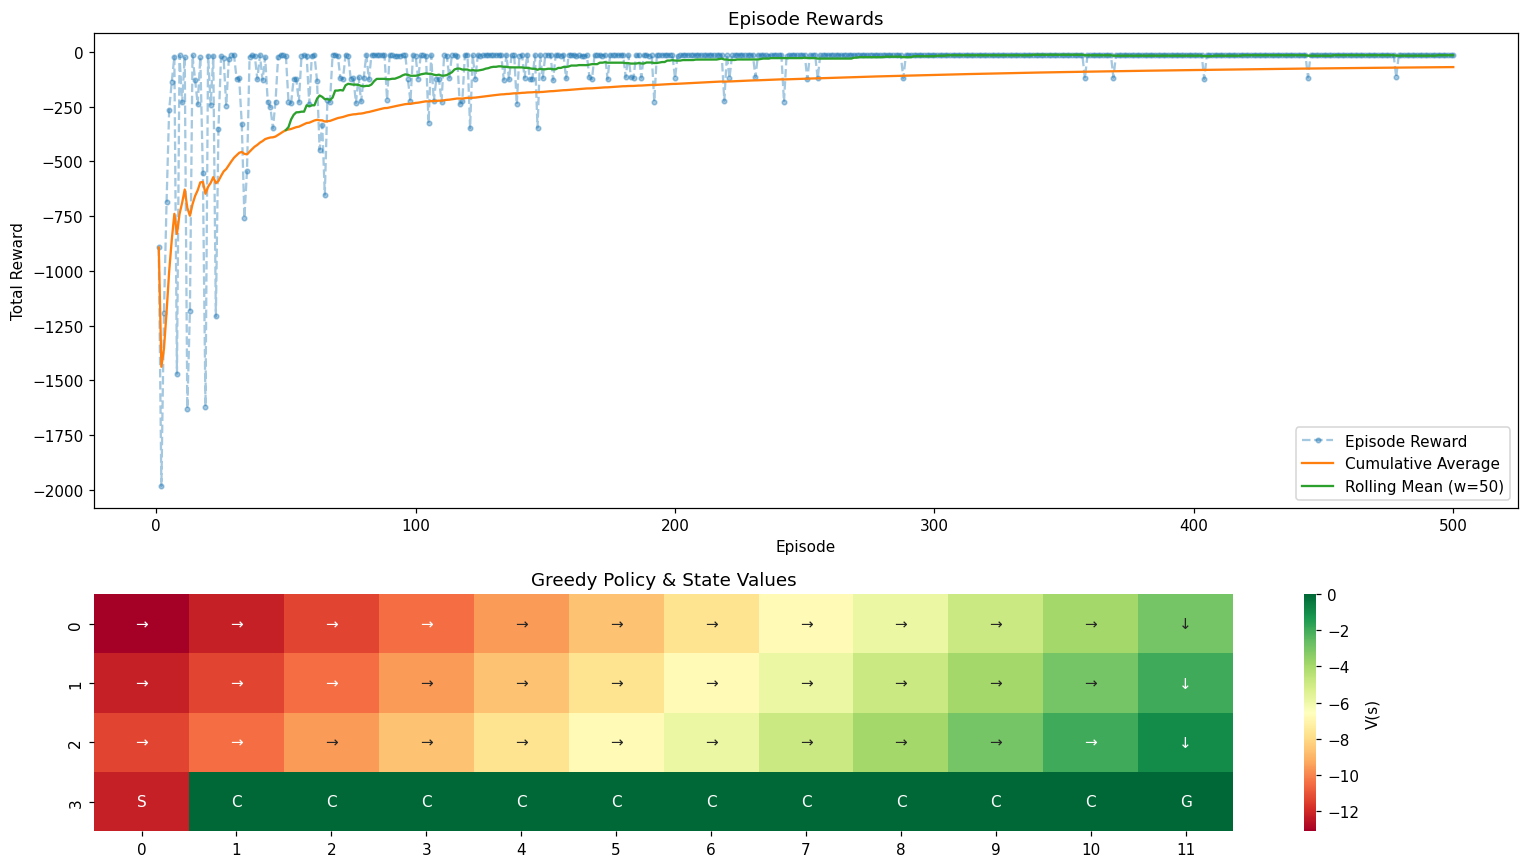

In [ ]:
# TODO: Implement and evaluate your improvement here.
# Leave previous experiments untouched so we can see the before/after.
def dyna_q_v2(n_episodes: int, env: gym.Env, epsilon_start: float, epsilon_min: float, decay: float ,alpha: float,
           gamma: float, n: int, max_steps: int = 200) -> tuple[np.ndarray, np.ndarray]:
    """Dyna-Q for a deterministic environment."""

    reward_sums = np.zeros(n_episodes)
    q = np.zeros((env.observation_space.n, env.action_space.n))
    model = defaultdict(dict)

    epsilon = epsilon_start

    for episode_i in (pbar := trange(n_episodes, leave=False)):
        state, info = env.reset()
        reward_sum, terminal, steps = 0.0, False, 0

        while not terminal and steps < max_steps:
            # TODO: 1. Select an action via epsilon-greedy.
            action = epsilon_greedy_policy(state, q, epsilon)

            # TODO: 2. Step the environment.
            next_state, reward, terminated, truncated, info = env.step(action)
            terminal = terminated or truncated

            # TODO: 3. Direct Q-learning update.
            q[state, action] += alpha * (reward + gamma * np.max(q[next_state]) - q[state, action])

            # TODO: 4. Update the deterministic model.
            model[state][action] = (reward, next_state)

            # TODO: 5. Planning step(s).
            q = q_planning(model, q, alpha, gamma, n)

            # TODO: 6. Bookkeeping: state <- next_state; accumulate reward; increment steps.
            state = next_state
            reward_sum += reward
            steps += 1

        epsilon = max(epsilon_min, epsilon * decay)

        pbar.set_description(f'Episode {episode_i}, R={reward_sum:.0f}')
        reward_sums[episode_i] = reward_sum

    return q, reward_sums

np.random.seed(2025)
random.seed(2025)
env = gym.make('CliffWalking-v1')

q_decay, R_decay = dyna_q_v2(
    n_episodes=500, env=env,
    epsilon_start=0.5,
    epsilon_min=0.01,
    decay=0.99,
    alpha=0.5,
    gamma=0.99,
    n=10
)

# Plot comparison: fixed epsilon vs decaying epsilon
fig, ax = plt.subplots(figsize=(10, 5))
window = 50

smooth_fixed = np.convolve(R_dyna, np.ones(window)/window, mode='valid')
smooth_decay = np.convolve(R_decay, np.ones(window)/window, mode='valid')

ax.plot(range(window, 501), smooth_fixed, label='Fixed ε=0.1')
ax.plot(range(window, 501), smooth_decay, label='Decaying ε (0.5→0.01)')
ax.set(xlabel='Episode', ylabel=f'Rolling Mean Reward (w={window})',
       title='Dyna-Q: Fixed vs Decaying ε')
ax.legend()
plt.tight_layout()
plt.show()

plot_performance(env, q_decay, R_decay)


In [19]:
print(np.max(R_decay))
print(np.max(R_dyna))

-13.0
-13.0


# 6. Reward Shaping (10 points)

**Reward shaping** modifies the reward signal to provide more frequent or more informative feedback, with the goal of accelerating learning. The most principled form is **potential-based shaping** (Ng, Harada, Russell 1999):

$$
F(s, a, s') = \gamma \Phi(s') - \Phi(s)
$$

where $\Phi : \mathcal{S} \to \mathbb{R}$ is any potential function. A foundational theorem states:

> *Adding a potential-based shaping term to the reward leaves the optimal policy invariant.*

Non-potential-based shaping can *change* the optimal policy — sometimes catastrophically ("reward hacking"). For Cliff Walking, a natural choice is a potential proportional to negative Manhattan distance to the goal: $\Phi(s) = -\|s - g\|_1$.

**Question 6.1.** Why does potential-based shaping preserve the optimal policy? Sketch the argument.

`Your Answers:`

Potential-based shaping preserves the optimal policy because the shaping term $F(s,a,s') = \gamma\Phi(s') - \Phi(s)$ is a *telescoping* difference. When summed over a complete trajectory, all intermediate potential terms cancel out, leaving only $\gamma^T\Phi(s_T) - \Phi(s_0)$ — a constant that depends only on the start and end states, not on which path was taken. Therefore, the *ordering* of trajectories by return is unchanged, and the optimal policy under the shaped reward is identical to the optimal policy under the original reward.

**Question 6.2.** Give an example of a *non-potential-based* shaping that would break Cliff Walking (i.e., cause the agent to learn a suboptimal policy).

`Your Answers:`

Suppose we add a bonus of $+10$ every time the agent moves *right*, regardless of where it is. This non-potential-based shaping incentivizes the agent to move right as much as possible, which would cause it to greedily walk along the bottom row directly into the cliff to collect right-movement bonuses — learning a catastrophically suboptimal policy that repeatedly falls off the cliff instead of reaching the goal safely.

In [20]:
from gymnasium.envs.toy_text import CliffWalkingEnv

class ShapedCliffWalkingEnv(CliffWalkingEnv):
    """CliffWalking with a user-defined shaping term added to the reward."""

    GOAL_STATE = 47  # index of the goal cell in the 4x12 grid
    NROWS, NCOLS = 4, 12

    def __init__(self, gamma: float = 0.99, **kwargs):
        super().__init__(**kwargs)
        self.gamma = gamma
        self._prev_state = None

    def reset(self, **kwargs):
        obs, info = super().reset(**kwargs)
        self._prev_state = obs
        return obs, info

    def potential(self, state: int) -> float:
        # TODO: Define Phi(state). For example, negative Manhattan distance to the goal.
        row, col = divmod(state, self.NCOLS)
        goal_row, goal_col = divmod(self.GOAL_STATE, self.NCOLS)
        return -(abs(row - goal_row) + abs(col - goal_col))

    def step(self, action):
        obs, reward, terminated, truncated, info = super().step(action)
        # TODO: Compute potential-based shaping F = gamma * Phi(obs) - Phi(self._prev_state)
        # and add it to reward.
        shaping = self.gamma * self.potential(obs) - self.potential(self._prev_state)
        shaped_reward = reward + shaping
        self._prev_state = obs
        return obs, shaped_reward, terminated, truncated, info

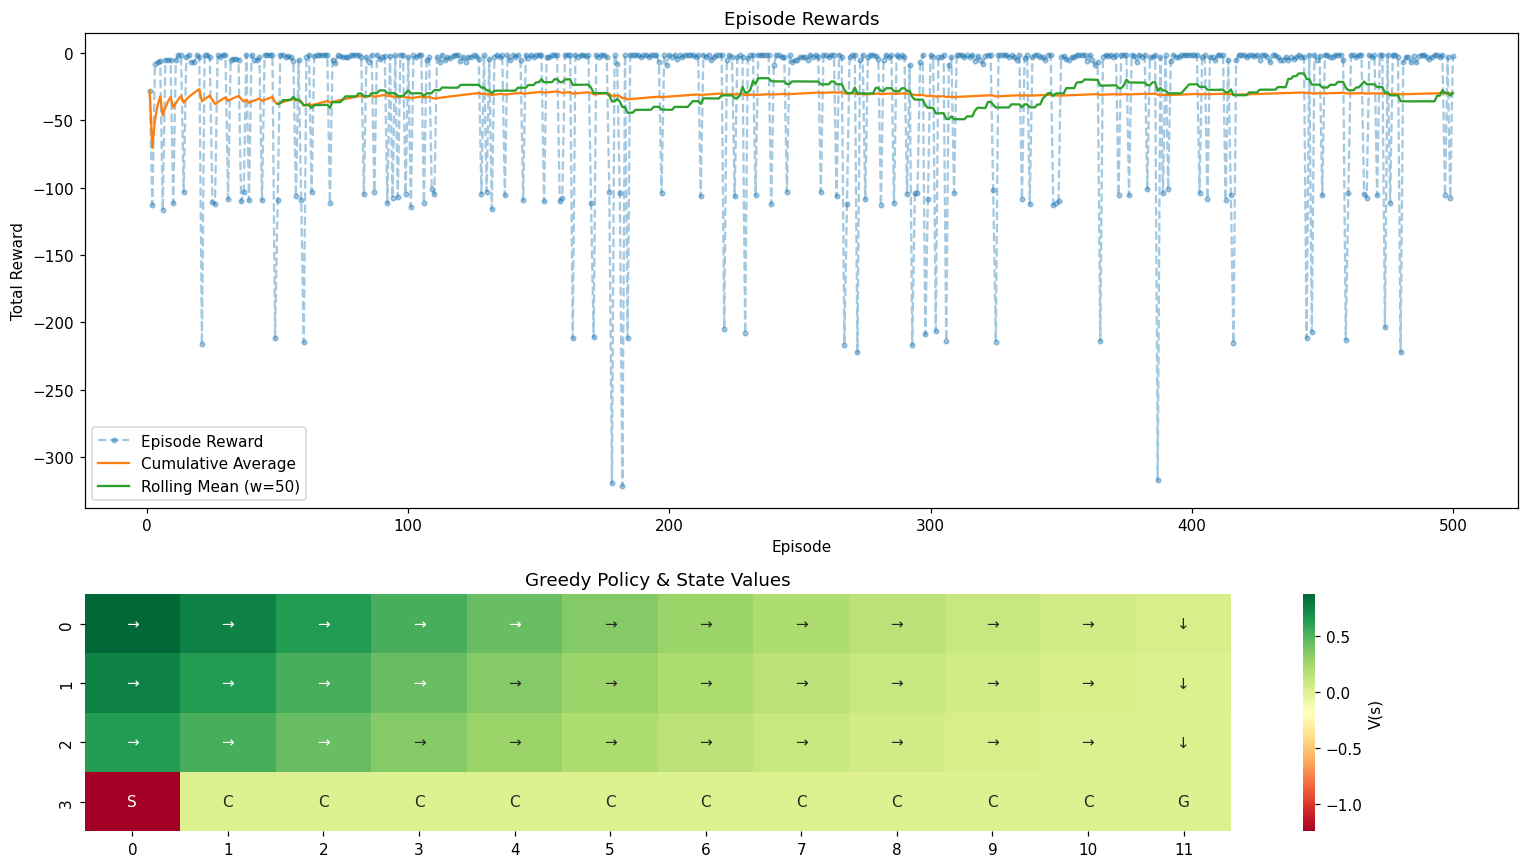

In [21]:
np.random.seed(2025)
random.seed(2025)

params = {
    'epsilon': 0.1,
    'alpha':   0.5,
    'gamma':   0.99,
    'n':       10,
}
n_episodes = 500

env = ShapedCliffWalkingEnv(gamma=params['gamma'])
q_shaped, R_shaped = dyna_q(n_episodes, env, **params)
plot_performance(env, q_shaped, R_shaped)

**Question 6.3.** Compare the learning curves with and without shaping. Did shaping help in the *early* episodes? In the *late* episodes? Why?

`Your Answer:`

Reward shaping significantly accelerated early learning — the shaped agent converged 
before episode 50, while plain Dyna-Q took much longer. In later episodes, both agents 
learned the same optimal policy (as confirmed by identical heatmaps), which is expected 
since potential-based shaping preserves the optimal policy by design. The apparent 
difference in reward scale is not a performance degradation but a natural consequence 
of the added shaping term modifying the reward magnitude.

# 7. Prioritized Sweeping (20 points)

Uniform sampling of $(s, a)$ pairs in the planning loop is wasteful. Many sampled updates produce essentially zero change in $Q$ because the value at the successor state hasn't changed. **Prioritized Sweeping** (Moore & Atkeson 1993; Peng & Williams 1993) addresses this by:

1. Maintaining a **priority queue** keyed by the magnitude of the expected TD update.
2. On each real step, computing the TD error $\delta$ for the current $(s, a)$. If $|\delta| > \theta$ (a threshold), push $(s, a)$ onto the queue with priority $|\delta|$.
3. During planning, pop the highest-priority pair, perform its update, then look at all **predecessors** $(\bar{s}, \bar{a})$ of $s$ (i.e., pairs known by the model to lead to $s$). Compute *their* TD errors; if they exceed $\theta$, push them too.

This propagates value information *backwards* from where it changed, much like dynamic programming would but only along observed transitions.

**Question 7.1.** Why is the magnitude of the TD error a sensible priority? What property does it estimate?

`Your Answers:`
The TD error $|\delta| = |r + \gamma \max_{a'} Q(s', a') - Q(s, a)|$ measures how *surprising* a transition is — i.e., how much our current Q-value differs from the bootstrapped target. A large TD error means the Q-value at $(s, a)$ is significantly wrong and will change substantially when updated. Therefore, prioritizing large TD errors ensures we spend planning budget on updates that actually move Q-values, propagating information efficiently rather than wasting updates on already-accurate estimates.


**Question 7.2.** Python's `heapq` is a *min-heap*. How do you use it as a *max-heap* for priorities?

`Your Answers:`

Python's `heapq` always pops the *smallest* element. To simulate a max-heap, store the **negative** of the priority: push $(-|\delta|, (s, a))$ so that the pair with the largest $|\delta|$ has the smallest negative value and gets popped first.


**Question 7.3.** What is the role of $\theta$? What happens if $\theta = 0$? If $\theta$ is very large?

`Your Answers:`
$\theta$ filters out insignificant updates to keep the heap small and efficient. 
If $\theta = 0$, every transition enters the heap regardless of its TD error — 
the heap grows very large and wastes memory and computation managing near-zero 
updates, even though prioritization is still maintained. If $\theta$ is very large, 
almost no transitions ever enter the queue and planning effectively never happens, 
reducing Prioritized Sweeping to plain Q-learning with no planning benefit.

## 7.1 Priority Planning (10 points)

Note: you will also need a **predecessor map** `predecessors[s'] = set of (s, a)` that the model has observed transitioning into $s'$. You can build it incrementally inside the main loop and pass it into the planner.

In [29]:
def q_planning_priority(model: dict, predecessors: dict, q: np.ndarray,
                        priorities: list, alpha: float, gamma: float,
                        n: int, theta: float) -> np.ndarray:
    """Perform up to n planning updates using prioritized sweeping."""
    seen = set()

    # TODO: Loop up to n times, breaking early if the queue is empty.
    for _ in range(n):
        if not priorities:
            break

    #   1. Pop the highest-priority (s, a) from `priorities`.
    #      (Remember: heapq is a min-heap, so store -|delta| to simulate max-heap.)
        _, (s, a) = heappop(priorities)
        if (s, a) in seen:  # skip duplicates
            continue
        seen.add((s, a))
        
    #   2. Look up (r, s') from model[s][a]. Perform the Q-learning update.
        r, s_next = model[s][a]
        q[s, a] += alpha * (r + gamma * np.max(q[s_next]) - q[s, a])

    #   3. For each predecessor (s_bar, a_bar) of s:
    #         retrieve (r_bar, _) = model[s_bar][a_bar]
    #         compute delta_bar = r_bar + gamma * max_a Q(s, a) - Q(s_bar, a_bar)
    #         if |delta_bar| > theta, push (-|delta_bar|, (s_bar, a_bar)) onto the heap.
        for s_bar, a_bar in predecessors[s]:
            r_bar, _ = model[s_bar][a_bar]
            delta_bar = r_bar + gamma * np.max(q[s]) - q[s_bar, a_bar]
            if abs(delta_bar) > theta:
                heappush(priorities, (-abs(delta_bar), (s_bar, a_bar)))
                
    return q

## 7.2 Learning with Prioritized Sweeping (10 points)

In [30]:
def dyna_q_priority(n_episodes: int, env: gym.Env, epsilon: float, alpha: float,
                   gamma: float, n: int, theta: float,
                   max_steps: int = 200) -> tuple[np.ndarray, np.ndarray]:
    """Dyna-Q with prioritized sweeping (deterministic model)."""

    reward_sums = np.zeros(n_episodes)
    q = np.zeros((env.observation_space.n, env.action_space.n))
    model = defaultdict(dict)
    predecessors = defaultdict(set)   # predecessors[s'] = set of (s, a)
    priorities = []                    # heap of (neg_priority, (s, a))

    for episode_i in (pbar := trange(n_episodes, leave=False)):
        state, info = env.reset()
        reward_sum, terminal, steps = 0.0, False, 0

        while not terminal and steps < max_steps:
            # TODO: 1. Select action via epsilon-greedy.
            action = epsilon_greedy_policy(state, q, epsilon)

            # TODO 2. Step environment
            next_state, reward, terminated, truncated, info = env.step(action)
            terminal = terminated or truncated

            # TODO 3. Direct Q-learning update
            q[state, action] += alpha * (reward + gamma * np.max(q[next_state]) - q[state, action])

            # TODO 4. Update model and predecessor map
            model[state][action] = (reward, next_state)
            predecessors[next_state].add((state, action))

            # TODO: 5. Compute the TD error; if |delta| > theta, push onto the priority queue.
            delta = reward + gamma * np.max(q[next_state]) - q[state, action]
            if abs(delta) > theta:
                heappush(priorities, (-abs(delta), (state, action)))

            # TODO: 6. Call q_planning_priority(...) with the queue.
            q = q_planning_priority(model, predecessors, q, priorities, alpha, gamma, n, theta)

            # TODO: 7. Bookkeeping.
            state = next_state
            reward_sum += reward
            steps += 1
            pass

        pbar.set_description(f'Episode {episode_i}, R={reward_sum:.0f}')
        reward_sums[episode_i] = reward_sum

    return q, reward_sums

# 8. Final Experiments (5 points)

Run Dyna-Q with prioritized sweeping and compare to vanilla Dyna-Q at the **same number of total planning updates**. Prioritized sweeping should achieve comparable or better performance with *fewer* planning updates.

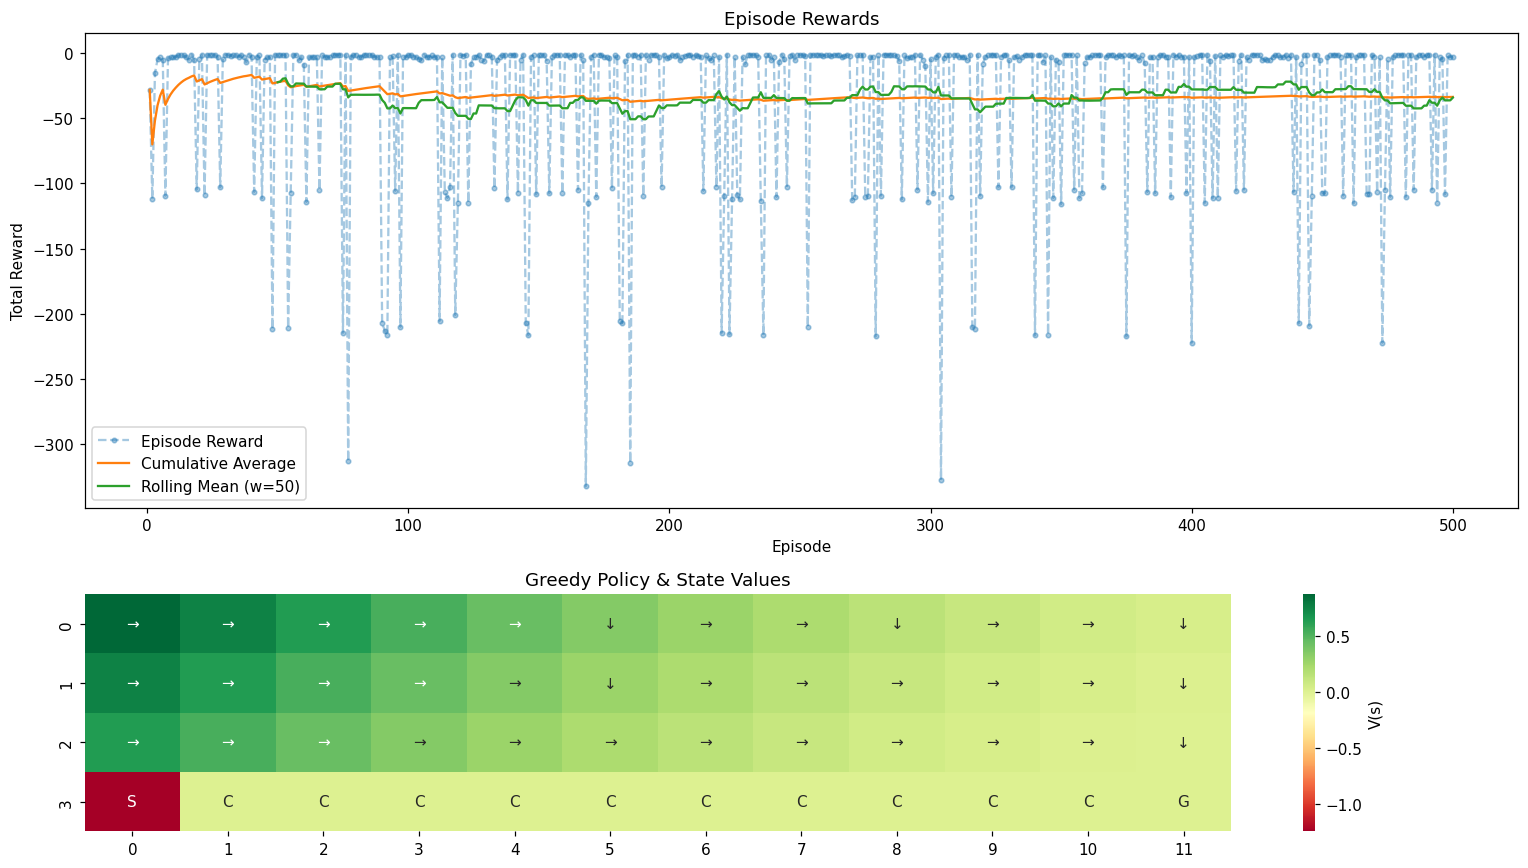

In [31]:
np.random.seed(2025)
random.seed(2025)

params = {
    'epsilon': 0.1,
    'alpha':   0.5,
    'gamma':   0.99,
    'n':       10,
    'theta':   1e-3,   # priority threshold
}
n_episodes = 500

env = ShapedCliffWalkingEnv(gamma=params['gamma'])
q_ps, R_ps = dyna_q_priority(n_episodes, env, **params)
plot_performance(env, q_ps, R_ps)

Visualize the learned greedy policy.

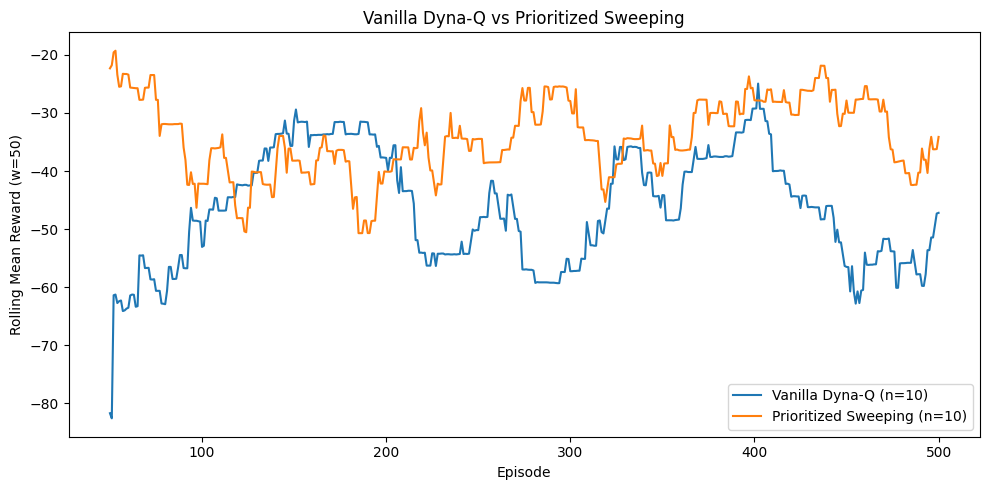

In [32]:
# Plot comparison using already computed results
fig, ax = plt.subplots(figsize=(10, 5))

window = 50
smooth_vanilla = np.convolve(R_dyna, np.ones(window)/window, mode='valid')
smooth_ps      = np.convolve(R_ps,   np.ones(window)/window, mode='valid')
xs = range(window, n_episodes + 1)

ax.plot(xs, smooth_vanilla, label='Vanilla Dyna-Q (n=10)')
ax.plot(xs, smooth_ps,      label='Prioritized Sweeping (n=10)')
ax.set(xlabel='Episode', ylabel=f'Rolling Mean Reward (w={window})',
       title='Vanilla Dyna-Q vs Prioritized Sweeping')
ax.legend()
plt.tight_layout()
plt.show()

In [33]:
env_vis = ShapedCliffWalkingEnv(gamma=params['gamma'], render_mode='rgb_array')
create_policy_eval_video(env_vis, greedy_policy, 'DynaQ_PS', Q=q_ps, max_steps=50)

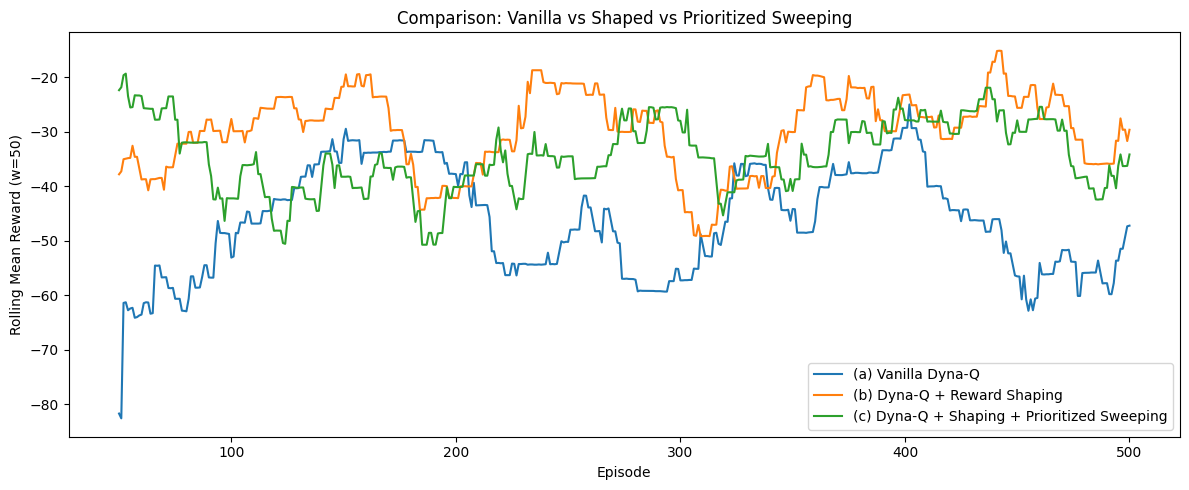

In [34]:
fig, ax = plt.subplots(figsize=(12, 5))

window = 50
smooth_vanilla = np.convolve(R_dyna, np.ones(window)/window, mode='valid')
smooth_shaped  = np.convolve(R_shaped, np.ones(window)/window, mode='valid')
smooth_ps      = np.convolve(R_ps,   np.ones(window)/window, mode='valid')
xs = range(window, n_episodes + 1)

ax.plot(xs, smooth_vanilla, label='(a) Vanilla Dyna-Q')
ax.plot(xs, smooth_shaped,  label='(b) Dyna-Q + Reward Shaping')
ax.plot(xs, smooth_ps,      label='(c) Dyna-Q + Shaping + Prioritized Sweeping')
ax.set(xlabel='Episode', ylabel=f'Rolling Mean Reward (w={window})',
       title='Comparison: Vanilla vs Shaped vs Prioritized Sweeping')
ax.legend()
plt.tight_layout()
plt.show()

**Question 8.1.** Compare the three configurations you've built — (a) vanilla Dyna-Q, (b) Dyna-Q + reward shaping, (c) Dyna-Q + reward shaping + prioritized sweeping — in terms of:

- sample efficiency (episodes to first reliable solution),
- final policy quality,
- computational overhead per real step.

Which is the most cost-effective in your view, and why?

`Your Answer:`

- **Sample efficiency:** (c) Prioritized Sweeping converges fastest in early episodes (before episode 100), followed closely by (b) Reward Shaping. Both significantly outperform (a) Vanilla Dyna-Q which remains around $-60$ for the first 100 episodes. In later episodes, (b) and (c) perform comparably, which is expected given the small state space of Cliff Walking.

- **Final policy quality:** All three configurations learned the optimal policy by the end of training. The remaining differences in rolling mean reward are due to the fixed $\varepsilon=0.1$ causing occasional random cliff falls, not differences in the learned policy itself.

- **Computational overhead per real step:** (a) Vanilla Dyna-Q has the lowest overhead — $O(n)$ uniform planning updates per step. (b) Reward Shaping adds only a constant-time potential computation with negligible cost. (c) Prioritized Sweeping adds heap operations ($O(\log k)$ per push/pop where $k$ is heap size) and predecessor lookups, making it the most expensive per real step.

- **Most cost-effective:** (b) Dyna-Q + Reward Shaping offers the best trade-off — it achieves the fastest convergence with minimal computational overhead, requiring only a simple potential function evaluation at each step. Prioritized Sweeping adds complexity and overhead that is more justified in larger state spaces where uniform planning is truly wasteful.

# 9. Bonus (10 points)

If you'd like to push further, attempt **one** of the following:

**Option A — Stochastic Dyna-Q.** Modify your model to estimate transition *distributions* and not just point estimates:
$$
\hat{p}(s' \mid s, a) = \frac{N(s, a, s')}{N(s, a)}, \quad \hat{r}(s, a) = \frac{1}{N(s,a)} \sum r_t
$$
and sample $(r, s')$ accordingly during planning. Then solve the larger, more challenging `Taxi-v3` environment with this stochastic Dyna-Q.

**Option B — Dyna-Q+ (exploration bonus).** Implement the Dyna-Q+ variant (Sutton & Barto §8.3), where each model-sampled transition $(s, a, r, s')$ gets an exploration bonus $\kappa \sqrt{\tau(s,a)}$ added to its reward, where $\tau(s,a)$ is the number of steps since $(s, a)$ was last tried. Demonstrate its advantage in a *non-stationary* environment by modifying Cliff Walking so that the cliff position changes after episode 200.

Document your design choices clearly and discuss results.

Taxi-v3 | States: 500 | Actions: 6


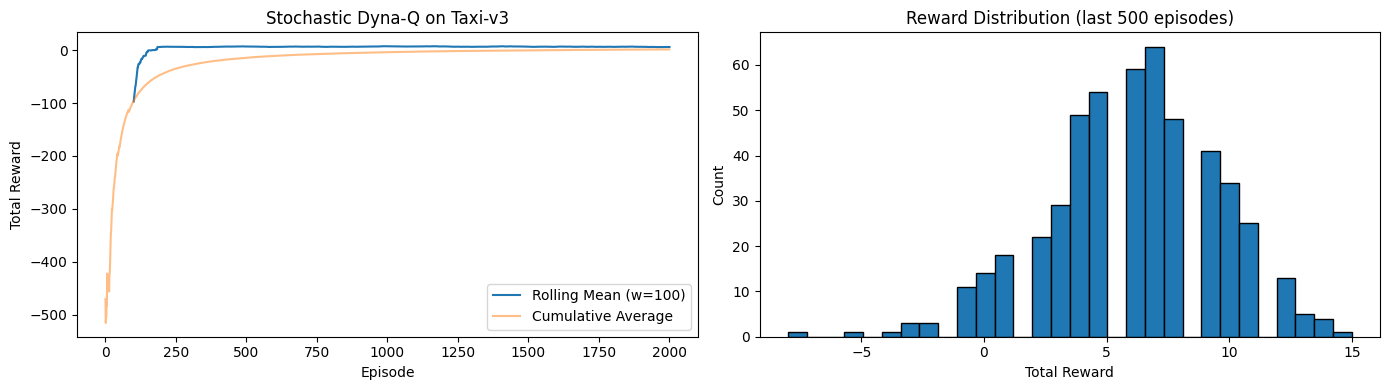

In [ ]:
# @title 🚶‍♂️ Happy Planning 🧠

def dyna_q_stochastic(n_episodes: int, env: gym.Env, epsilon: float, alpha: float,
                      gamma: float, n: int, max_steps: int = 200) -> tuple[np.ndarray, np.ndarray]:
    """Dyna-Q with a stochastic model: stores transition counts and average rewards."""

    reward_sums = np.zeros(n_episodes)
    q = np.zeros((env.observation_space.n, env.action_space.n))


    N       = defaultdict(lambda: defaultdict(lambda: defaultdict(int)))
    R_sum   = defaultdict(lambda: defaultdict(float))
    N_sa    = defaultdict(lambda: defaultdict(int))

    for episode_i in (pbar := trange(n_episodes, leave=False)):
        state, info = env.reset()
        reward_sum, terminal, steps = 0.0, False, 0

        while not terminal and steps < max_steps:
            # 1. epsilon-greedy
            action = epsilon_greedy_policy(state, q, epsilon)

            # 2. step environment
            next_state, reward, terminated, truncated, info = env.step(action)
            terminal = terminated or truncated

            # 3. direct Q-learning update
            q[state, action] += alpha * (reward + gamma * np.max(q[next_state]) - q[state, action])

            # 4. update stochastic model
            N[state][action][next_state] += 1
            R_sum[state][action]         += reward
            N_sa[state][action]          += 1

            # 5. planning with stochastic model
            for _ in range(n):
                if not N:
                    break
                # sample visited (s, a)
                s       = random.choice(list(N.keys()))
                a       = random.choice(list(N[s].keys()))
                n_total = N_sa[s][a]

                # sample s' from empirical distribution
                successors  = list(N[s][a].keys())
                probs       = [N[s][a][sp] / n_total for sp in successors]
                s_next      = random.choices(successors, weights=probs, k=1)[0]

                # average reward
                r_avg = R_sum[s][a] / n_total

                # Q-learning update on simulated transition
                q[s, a] += alpha * (r_avg + gamma * np.max(q[s_next]) - q[s, a])

            # 6. bookkeeping
            state       = next_state
            reward_sum  += reward
            steps       += 1

        pbar.set_description(f'Episode {episode_i}, R={reward_sum:.0f}')
        reward_sums[episode_i] = reward_sum

    return q, reward_sums


# Run on Taxi-v3
np.random.seed(2025)
random.seed(2025)

taxi_env = gym.make('Taxi-v3')
print('Taxi-v3 | States:', taxi_env.observation_space.n,
      '| Actions:', taxi_env.action_space.n)

taxi_episodes = 2000
taxi_params = {
    'epsilon': 0.1,
    'alpha':   0.5,
    'gamma':   0.99,
    'n':       10,
    'max_steps': 500,
}

q_taxi, R_taxi = dyna_q_stochastic(taxi_episodes, taxi_env, **taxi_params)

# Plot results
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

window = 100
smooth = np.convolve(R_taxi, np.ones(window)/window, mode='valid')
axes[0].plot(range(window, taxi_episodes + 1), smooth, label=f'Rolling Mean (w={window})')
axes[0].plot(np.cumsum(R_taxi) / np.arange(1, taxi_episodes + 1), 
             alpha=0.5, label='Cumulative Average')
axes[0].set(xlabel='Episode', ylabel='Total Reward',
            title='Stochastic Dyna-Q on Taxi-v3')
axes[0].legend()

# Right: histogram of rewards in last 500 episodes
axes[1].hist(R_taxi[-500:], bins=30, edgecolor='black')
axes[1].set(xlabel='Total Reward', ylabel='Count',
            title='Reward Distribution (last 500 episodes)')

plt.tight_layout()
plt.show()

In [36]:
# ─── Visualize Stochastic Dyna-Q on Taxi-v3 ───

taxi_env_render = gym.make('Taxi-v3', render_mode='rgb_array')
create_policy_eval_video(taxi_env_render, greedy_policy, 'taxi_stochastic_dyna', 
                         Q=q_taxi, num_episodes=3, max_steps=200)

IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (550, 350) to (560, 352) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).
